<a href="https://colab.research.google.com/github/ahttpsage/neural-networks-colab/blob/main/neural_network1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
base_path = "/content/drive/MyDrive/data_resource"

Mounted at /content/drive


In [ ]:
#!figsize and dpi
#!subplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import time
import string

import seaborn as sns
%matplotlib inline
#!numpy,matplotlib,pandas and seaborn



#!cuffkins and plotly


import cufflinks as cf
from plotly.offline import download_plotlyjs,init_notebook_mode,plot,iplot
init_notebook_mode(connected=True)#!connects to interactive js
import plotly.express as px
cf.go_offline()

#!sk learn
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sqlalchemy import create_engine

from sklearn.decomposition import PCA
#nlp
import pickle
import nltk
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfTransformer,TfidfVectorizer
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import CountVectorizer
from nltk.stem import WordNetLemmatizer
from nltk.stem import PorterStemmer
from nltk.corpus import wordnet
from nltk.corpus import stopwords

#tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Input
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping,TensorBoard
from tensorflow.keras.datasets import mnist
#mode metric =>auto min max,loss accuracy etc

from datetime import datetime
from sklearn.compose import ColumnTransformer



In [ ]:

loan_data=pd.read_csv(f"{base_path}/lending_club_loan_two.csv")

In [ ]:
loan_data.head()


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\nGreggshire, VA 11650"


In [ ]:
loan_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 396030 entries, 0 to 396029
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   loan_amnt             396030 non-null  float64
 1   term                  396030 non-null  object 
 2   int_rate              396030 non-null  float64
 3   installment           396030 non-null  float64
 4   grade                 396030 non-null  object 
 5   sub_grade             396030 non-null  object 
 6   emp_title             373103 non-null  object 
 7   emp_length            377729 non-null  object 
 8   home_ownership        396030 non-null  object 
 9   annual_inc            396030 non-null  float64
 10  verification_status   396030 non-null  object 
 11  issue_d               396030 non-null  object 
 12  loan_status           396030 non-null  object 
 13  purpose               396030 non-null  object 
 14  title                 394274 non-null  object 
 15  

In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data.shape

(396030, 27)

In [ ]:
loan_data['loan_status'].value_counts()

,count
loan_status,
Fully Paid,318357
Charged Off,77673


In [ ]:
for colm in loan_data.select_dtypes(include=np.object_).columns.to_list():
  print(colm,loan_data[colm].nunique(),end="\n")

term 2
grade 7
sub_grade 35
emp_title 173105
emp_length 11
home_ownership 6
verification_status 3
issue_d 115
loan_status 2
purpose 14
title 48816
earliest_cr_line 684
initial_list_status 2
application_type 3
address 393700


In [ ]:
loan_data.select_dtypes(include=np.object_)

,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,purpose,title,earliest_cr_line,initial_list_status,application_type,address
0,36 months,B,B4,Marketing,10+ years,RENT,Not Verified,Jan-2015,Fully Paid,vacation,Vacation,Jun-1990,w,INDIVIDUAL,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,36 months,B,B5,Credit analyst,4 years,MORTGAGE,Not Verified,Jan-2015,Fully Paid,debt_consolidation,Debt consolidation,Jul-2004,f,INDIVIDUAL,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,36 months,B,B3,Statistician,< 1 year,RENT,Source Verified,Jan-2015,Fully Paid,credit_card,Credit card refinancing,Aug-2007,f,INDIVIDUAL,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,36 months,A,A2,Client Advocate,6 years,RENT,Not Verified,Nov-2014,Fully Paid,credit_card,Credit card refinancing,Sep-2006,f,INDIVIDUAL,"823 Reid Ford\nDelacruzside, MA 00813"
4,60 months,C,C5,Destiny Management Inc.,9 years,MORTGAGE,Verified,Apr-2013,Charged Off,credit_card,Credit Card Refinance,Mar-1999,f,INDIVIDUAL,"679 Luna Roads\nGreggshire, VA 11650"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396025,60 months,B,B4,licensed bankere,2 years,RENT,Source Verified,Oct-2015,Fully Paid,debt_consolidation,Debt consolidation,Nov-2004,w,INDIVIDUAL,"12951 Williams Crossing\nJohnnyville, DC 30723"
396026,36 months,C,C1,Agent,5 years,MORTGAGE,Source Verified,Feb-2015,Fully Paid,debt_consolidation,Debt consolidation,Feb-2006,f,INDIVIDUAL,"0114 Fowler Field Suite 028\nRachelborough, LA..."
396027,36 months,B,B1,City Carrier,10+ years,RENT,Verified,Oct-2013,Fully Paid,debt_consolidation,pay off credit cards,Mar-1997,f,INDIVIDUAL,"953 Matthew Points Suite 414\nReedfort, NY 70466"
396028,60 months,C,C2,"Gracon Services, Inc",10+ years,MORTGAGE,Verified,Aug-2012,Fully Paid,debt_consolidation,Loanforpayoff,Nov-1990,f,INDIVIDUAL,"7843 Blake Freeway Apt. 229\nNew Michael, FL 2..."


In [ ]:
loan_data['loan_status']=loan_data['loan_status'].apply(func=lambda x:1 if "paid" in x.lower() else 0)

In [ ]:
loan_data['loan_status']

,loan_status
0,1
1,1
2,1
3,1
4,0
...,...
396025,1
396026,1
396027,1
396028,1


In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data.select_dtypes(include=np.object_)

,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,purpose,title,earliest_cr_line,initial_list_status,application_type,address
0,36 months,B,B4,Marketing,10+ years,RENT,Not Verified,Jan-2015,vacation,Vacation,Jun-1990,w,INDIVIDUAL,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,36 months,B,B5,Credit analyst,4 years,MORTGAGE,Not Verified,Jan-2015,debt_consolidation,Debt consolidation,Jul-2004,f,INDIVIDUAL,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,36 months,B,B3,Statistician,< 1 year,RENT,Source Verified,Jan-2015,credit_card,Credit card refinancing,Aug-2007,f,INDIVIDUAL,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,36 months,A,A2,Client Advocate,6 years,RENT,Not Verified,Nov-2014,credit_card,Credit card refinancing,Sep-2006,f,INDIVIDUAL,"823 Reid Ford\nDelacruzside, MA 00813"
4,60 months,C,C5,Destiny Management Inc.,9 years,MORTGAGE,Verified,Apr-2013,credit_card,Credit Card Refinance,Mar-1999,f,INDIVIDUAL,"679 Luna Roads\nGreggshire, VA 11650"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396025,60 months,B,B4,licensed bankere,2 years,RENT,Source Verified,Oct-2015,debt_consolidation,Debt consolidation,Nov-2004,w,INDIVIDUAL,"12951 Williams Crossing\nJohnnyville, DC 30723"
396026,36 months,C,C1,Agent,5 years,MORTGAGE,Source Verified,Feb-2015,debt_consolidation,Debt consolidation,Feb-2006,f,INDIVIDUAL,"0114 Fowler Field Suite 028\nRachelborough, LA..."
396027,36 months,B,B1,City Carrier,10+ years,RENT,Verified,Oct-2013,debt_consolidation,pay off credit cards,Mar-1997,f,INDIVIDUAL,"953 Matthew Points Suite 414\nReedfort, NY 70466"
396028,60 months,C,C2,"Gracon Services, Inc",10+ years,MORTGAGE,Verified,Aug-2012,debt_consolidation,Loanforpayoff,Nov-1990,f,INDIVIDUAL,"7843 Blake Freeway Apt. 229\nNew Michael, FL 2..."


In [ ]:
loan_data['term']=loan_data['term'].apply(lambda x:int(x.split()[0]))

In [ ]:
loan_data

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,8000.0,36,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,15600.0,36,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,7200.0,36,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\nDelacruzside, MA 00813"
4,24375.0,60,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\nGreggshire, VA 11650"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396025,10000.0,60,10.99,217.38,B,B4,licensed bankere,2 years,RENT,40000.0,...,6.0,0.0,1990.0,34.3,23.0,w,INDIVIDUAL,0.0,0.0,"12951 Williams Crossing\nJohnnyville, DC 30723"
396026,21000.0,36,12.29,700.42,C,C1,Agent,5 years,MORTGAGE,110000.0,...,6.0,0.0,43263.0,95.7,8.0,f,INDIVIDUAL,1.0,0.0,"0114 Fowler Field Suite 028\nRachelborough, LA..."
396027,5000.0,36,9.99,161.32,B,B1,City Carrier,10+ years,RENT,56500.0,...,15.0,0.0,32704.0,66.9,23.0,f,INDIVIDUAL,0.0,0.0,"953 Matthew Points Suite 414\nReedfort, NY 70466"
396028,21000.0,60,15.31,503.02,C,C2,"Gracon Services, Inc",10+ years,MORTGAGE,64000.0,...,9.0,0.0,15704.0,53.8,20.0,f,INDIVIDUAL,5.0,0.0,"7843 Blake Freeway Apt. 229\nNew Michael, FL 2..."


In [ ]:
loan_data.select_dtypes(include=np.object_)

,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,purpose,title,earliest_cr_line,initial_list_status,application_type,address
0,B,B4,Marketing,10+ years,RENT,Not Verified,Jan-2015,vacation,Vacation,Jun-1990,w,INDIVIDUAL,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,B,B5,Credit analyst,4 years,MORTGAGE,Not Verified,Jan-2015,debt_consolidation,Debt consolidation,Jul-2004,f,INDIVIDUAL,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,B,B3,Statistician,< 1 year,RENT,Source Verified,Jan-2015,credit_card,Credit card refinancing,Aug-2007,f,INDIVIDUAL,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,A,A2,Client Advocate,6 years,RENT,Not Verified,Nov-2014,credit_card,Credit card refinancing,Sep-2006,f,INDIVIDUAL,"823 Reid Ford\nDelacruzside, MA 00813"
4,C,C5,Destiny Management Inc.,9 years,MORTGAGE,Verified,Apr-2013,credit_card,Credit Card Refinance,Mar-1999,f,INDIVIDUAL,"679 Luna Roads\nGreggshire, VA 11650"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
396025,B,B4,licensed bankere,2 years,RENT,Source Verified,Oct-2015,debt_consolidation,Debt consolidation,Nov-2004,w,INDIVIDUAL,"12951 Williams Crossing\nJohnnyville, DC 30723"
396026,C,C1,Agent,5 years,MORTGAGE,Source Verified,Feb-2015,debt_consolidation,Debt consolidation,Feb-2006,f,INDIVIDUAL,"0114 Fowler Field Suite 028\nRachelborough, LA..."
396027,B,B1,City Carrier,10+ years,RENT,Verified,Oct-2013,debt_consolidation,pay off credit cards,Mar-1997,f,INDIVIDUAL,"953 Matthew Points Suite 414\nReedfort, NY 70466"
396028,C,C2,"Gracon Services, Inc",10+ years,MORTGAGE,Verified,Aug-2012,debt_consolidation,Loanforpayoff,Nov-1990,f,INDIVIDUAL,"7843 Blake Freeway Apt. 229\nNew Michael, FL 2..."


In [ ]:
from datetime import date

In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
def age_compute_func(year_str):
  year_val=int(year_str.split("-")[1])
  current_year = date.today().year
  age=current_year-year_val
  return age


In [ ]:
loan_data['issue_d']=loan_data['issue_d'].apply(age_compute_func)

In [ ]:
loan_data.head(3)

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,8000.0,36,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,15600.0,36,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"


In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data['earliest_cr_line']=loan_data['earliest_cr_line'].apply(age_compute_func)

In [ ]:
loan_data['earliest_cr_line']

,earliest_cr_line
0,36
1,22
2,19
3,20
4,27
...,...
396025,22
396026,20
396027,29
396028,36


In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data.select_dtypes(include=np.object_)

,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,purpose,title,initial_list_status,application_type,address
0,B,B4,Marketing,10+ years,RENT,Not Verified,vacation,Vacation,w,INDIVIDUAL,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,B,B5,Credit analyst,4 years,MORTGAGE,Not Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,B,B3,Statistician,< 1 year,RENT,Source Verified,credit_card,Credit card refinancing,f,INDIVIDUAL,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,A,A2,Client Advocate,6 years,RENT,Not Verified,credit_card,Credit card refinancing,f,INDIVIDUAL,"823 Reid Ford\nDelacruzside, MA 00813"
4,C,C5,Destiny Management Inc.,9 years,MORTGAGE,Verified,credit_card,Credit Card Refinance,f,INDIVIDUAL,"679 Luna Roads\nGreggshire, VA 11650"
...,...,...,...,...,...,...,...,...,...,...,...
396025,B,B4,licensed bankere,2 years,RENT,Source Verified,debt_consolidation,Debt consolidation,w,INDIVIDUAL,"12951 Williams Crossing\nJohnnyville, DC 30723"
396026,C,C1,Agent,5 years,MORTGAGE,Source Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL,"0114 Fowler Field Suite 028\nRachelborough, LA..."
396027,B,B1,City Carrier,10+ years,RENT,Verified,debt_consolidation,pay off credit cards,f,INDIVIDUAL,"953 Matthew Points Suite 414\nReedfort, NY 70466"
396028,C,C2,"Gracon Services, Inc",10+ years,MORTGAGE,Verified,debt_consolidation,Loanforpayoff,f,INDIVIDUAL,"7843 Blake Freeway Apt. 229\nNew Michael, FL 2..."


In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data.drop(columns=['grade','address'],axis=1,inplace=True)

In [ ]:
loan_data.select_dtypes(include=np.object_)

,sub_grade,emp_title,emp_length,home_ownership,verification_status,purpose,title,initial_list_status,application_type
0,B4,Marketing,10+ years,RENT,Not Verified,vacation,Vacation,w,INDIVIDUAL
1,B5,Credit analyst,4 years,MORTGAGE,Not Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL
2,B3,Statistician,< 1 year,RENT,Source Verified,credit_card,Credit card refinancing,f,INDIVIDUAL
3,A2,Client Advocate,6 years,RENT,Not Verified,credit_card,Credit card refinancing,f,INDIVIDUAL
4,C5,Destiny Management Inc.,9 years,MORTGAGE,Verified,credit_card,Credit Card Refinance,f,INDIVIDUAL
...,...,...,...,...,...,...,...,...,...
396025,B4,licensed bankere,2 years,RENT,Source Verified,debt_consolidation,Debt consolidation,w,INDIVIDUAL
396026,C1,Agent,5 years,MORTGAGE,Source Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL
396027,B1,City Carrier,10+ years,RENT,Verified,debt_consolidation,pay off credit cards,f,INDIVIDUAL
396028,C2,"Gracon Services, Inc",10+ years,MORTGAGE,Verified,debt_consolidation,Loanforpayoff,f,INDIVIDUAL


In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
def get_emp_length(year_str):
  final=''
  if pd.isnull(year_str):
    return 0
  for char_val in year_str:
    if char_val in '0123456789':
      final+=char_val
  return int(final)


# def get_emp_length(year_str):
#     return int(''.join(filter(str.isdigit, year_str)))


In [ ]:
get_emp_length('10+ years')

10

In [ ]:
get_emp_length('<1 years')

1

In [ ]:

loan_data['emp_length'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 396030 entries, 0 to 396029
Series name: emp_length
Non-Null Count   Dtype 
--------------   ----- 
377729 non-null  object
dtypes: object(1)
memory usage: 3.0+ MB


In [ ]:
loan_data['emp_length'].value_counts()

,count
emp_length,
10+ years,126041
2 years,35827
< 1 year,31725
3 years,31665
5 years,26495
1 year,25882
4 years,23952
6 years,20841
7 years,20819


In [ ]:
loan_data['emp_length'].isna()

,emp_length
0,False
1,False
2,False
3,False
4,False
...,...
396025,False
396026,False
396027,False
396028,False


In [ ]:
loan_data['emp_length'].isnull()

,emp_length
0,False
1,False
2,False
3,False
4,False
...,...
396025,False
396026,False
396027,False
396028,False


In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data['year_time']=loan_data['emp_length'].apply(func=get_emp_length)

In [ ]:

loan_data['year_time']

,year_time
0,10
1,4
2,1
3,6
4,9
...,...
396025,2
396026,5
396027,10
396028,10


In [ ]:
loan_data.drop(columns=['emp_length'],axis=1,inplace=True)

In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data.select_dtypes(include=np.object_)

,sub_grade,emp_title,home_ownership,verification_status,purpose,title,initial_list_status,application_type
0,B4,Marketing,RENT,Not Verified,vacation,Vacation,w,INDIVIDUAL
1,B5,Credit analyst,MORTGAGE,Not Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL
2,B3,Statistician,RENT,Source Verified,credit_card,Credit card refinancing,f,INDIVIDUAL
3,A2,Client Advocate,RENT,Not Verified,credit_card,Credit card refinancing,f,INDIVIDUAL
4,C5,Destiny Management Inc.,MORTGAGE,Verified,credit_card,Credit Card Refinance,f,INDIVIDUAL
...,...,...,...,...,...,...,...,...
396025,B4,licensed bankere,RENT,Source Verified,debt_consolidation,Debt consolidation,w,INDIVIDUAL
396026,C1,Agent,MORTGAGE,Source Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL
396027,B1,City Carrier,RENT,Verified,debt_consolidation,pay off credit cards,f,INDIVIDUAL
396028,C2,"Gracon Services, Inc",MORTGAGE,Verified,debt_consolidation,Loanforpayoff,f,INDIVIDUAL


In [ ]:
# loan_data['emp_meta']=loan_data['emp_title'].apply(lambda x:type(x))

In [ ]:
# loan_data[loan_data['emp_meta']==str]
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data

,loan_amnt,term,int_rate,installment,sub_grade,emp_title,home_ownership,annual_inc,verification_status,issue_d,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,year_time
0,10000.0,36,11.44,329.48,B4,Marketing,RENT,117000.0,Not Verified,11,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,10
1,8000.0,36,11.99,265.68,B5,Credit analyst,MORTGAGE,65000.0,Not Verified,11,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,4
2,15600.0,36,10.49,506.97,B3,Statistician,RENT,43057.0,Source Verified,11,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,1
3,7200.0,36,6.49,220.65,A2,Client Advocate,RENT,54000.0,Not Verified,12,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,6
4,24375.0,60,17.27,609.33,C5,Destiny Management Inc.,MORTGAGE,55000.0,Verified,13,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396025,10000.0,60,10.99,217.38,B4,licensed bankere,RENT,40000.0,Source Verified,11,...,6.0,0.0,1990.0,34.3,23.0,w,INDIVIDUAL,0.0,0.0,2
396026,21000.0,36,12.29,700.42,C1,Agent,MORTGAGE,110000.0,Source Verified,11,...,6.0,0.0,43263.0,95.7,8.0,f,INDIVIDUAL,1.0,0.0,5
396027,5000.0,36,9.99,161.32,B1,City Carrier,RENT,56500.0,Verified,13,...,15.0,0.0,32704.0,66.9,23.0,f,INDIVIDUAL,0.0,0.0,10
396028,21000.0,60,15.31,503.02,C2,"Gracon Services, Inc",MORTGAGE,64000.0,Verified,14,...,9.0,0.0,15704.0,53.8,20.0,f,INDIVIDUAL,5.0,0.0,10


In [ ]:
def adv_emp_title(emp_title):
  if pd.isnull(emp_title):
    return "unclassified"
  emp_title_adv=emp_title.split()[0]
  return emp_title_adv


In [ ]:
loan_data['emp_title_adv']=loan_data['emp_title'].apply(func=adv_emp_title)

In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
def emp_classify(emp_title):
  if pd.isnull(emp_title):
    return "unclassified"
  emp_title=emp_title.lower()
  if "market" in emp_title:
    return "Marketing"
  elif "stat" in emp_title or "analyst" in emp_title or "bank" in emp_title:
    return "Analyst"
  elif "teach" in emp_title or "univ" in emp_title:
    return "Academic"
  elif "service" in emp_title:
    return "Service"
  elif "carrier" in emp_title:
    return "Logistic"
  elif "software" in emp_title or "code" in emp_title:
    return "IT"
  elif "doctor" in emp_title or "medic" in emp_title:
    return "Medicine"
  elif "logist" in emp_title:
    return "Specialist"
  else:
    return "Others"

In [ ]:
loan_data['emp_class']=loan_data['emp_title'].apply(emp_classify)

In [ ]:
loan_data['emp_class'].value_counts()

,count
emp_class,
Others,322981
unclassified,22927
Analyst,16394
Service,11545
Academic,9420
Medicine,4862
Marketing,2586
IT,2281
Specialist,2028


In [ ]:
loan_data.select_dtypes(include=np.object_)

,sub_grade,emp_title,home_ownership,verification_status,purpose,title,initial_list_status,application_type,emp_title_adv,emp_class
0,B4,Marketing,RENT,Not Verified,vacation,Vacation,w,INDIVIDUAL,Marketing,Marketing
1,B5,Credit analyst,MORTGAGE,Not Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL,Credit,Analyst
2,B3,Statistician,RENT,Source Verified,credit_card,Credit card refinancing,f,INDIVIDUAL,Statistician,Analyst
3,A2,Client Advocate,RENT,Not Verified,credit_card,Credit card refinancing,f,INDIVIDUAL,Client,Others
4,C5,Destiny Management Inc.,MORTGAGE,Verified,credit_card,Credit Card Refinance,f,INDIVIDUAL,Destiny,Others
...,...,...,...,...,...,...,...,...,...,...
396025,B4,licensed bankere,RENT,Source Verified,debt_consolidation,Debt consolidation,w,INDIVIDUAL,licensed,Analyst
396026,C1,Agent,MORTGAGE,Source Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL,Agent,Others
396027,B1,City Carrier,RENT,Verified,debt_consolidation,pay off credit cards,f,INDIVIDUAL,City,Logistic
396028,C2,"Gracon Services, Inc",MORTGAGE,Verified,debt_consolidation,Loanforpayoff,f,INDIVIDUAL,Gracon,Service


In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data['title'].value_counts()

,count
title,
Debt consolidation,152472
Credit card refinancing,51487
Home improvement,15264
Other,12930
Debt Consolidation,11608
...,...
creditcardrefi,1
Debt/Home,1
Peace Of Mind Loan,1


In [ ]:
def title_class(title_class):
  if pd.isnull(title_class):
    return "Unclassified"
  title_class=title_class.lower()
  if "debt" in title_class:
    return "Debt"
  elif "credit" in title_class and "card" in title_class:
    return "Credit Card"
  elif "univ" in title_class or "school" in title_class or "edu" in title_class:
    return "Education"
  elif "home" in title_class:
    return "Home"
  elif "health" in title_class or "medic" in title_class or "doctor" in title_class or "emergency" in title_class:
    return "Health"
  elif "purchase" in title_class or "buy" in title_class:
    return "Purchase"
  else:
    return "Others"

In [ ]:
loan_data['loan_class']=loan_data['title'].apply(title_class)

In [ ]:
loan_data.select_dtypes(include=np.object_)

,sub_grade,emp_title,home_ownership,verification_status,purpose,title,initial_list_status,application_type,emp_title_adv,emp_class,loan_class
0,B4,Marketing,RENT,Not Verified,vacation,Vacation,w,INDIVIDUAL,Marketing,Marketing,Others
1,B5,Credit analyst,MORTGAGE,Not Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL,Credit,Analyst,Debt
2,B3,Statistician,RENT,Source Verified,credit_card,Credit card refinancing,f,INDIVIDUAL,Statistician,Analyst,Credit Card
3,A2,Client Advocate,RENT,Not Verified,credit_card,Credit card refinancing,f,INDIVIDUAL,Client,Others,Credit Card
4,C5,Destiny Management Inc.,MORTGAGE,Verified,credit_card,Credit Card Refinance,f,INDIVIDUAL,Destiny,Others,Credit Card
...,...,...,...,...,...,...,...,...,...,...,...
396025,B4,licensed bankere,RENT,Source Verified,debt_consolidation,Debt consolidation,w,INDIVIDUAL,licensed,Analyst,Debt
396026,C1,Agent,MORTGAGE,Source Verified,debt_consolidation,Debt consolidation,f,INDIVIDUAL,Agent,Others,Debt
396027,B1,City Carrier,RENT,Verified,debt_consolidation,pay off credit cards,f,INDIVIDUAL,City,Logistic,Credit Card
396028,C2,"Gracon Services, Inc",MORTGAGE,Verified,debt_consolidation,Loanforpayoff,f,INDIVIDUAL,Gracon,Service,Others


In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data.drop(columns=['emp_title_adv','emp_title','title'],axis=1,inplace=True)

In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data.select_dtypes(include=np.object_)

,sub_grade,home_ownership,verification_status,purpose,initial_list_status,application_type,emp_class,loan_class
0,B4,RENT,Not Verified,vacation,w,INDIVIDUAL,Marketing,Others
1,B5,MORTGAGE,Not Verified,debt_consolidation,f,INDIVIDUAL,Analyst,Debt
2,B3,RENT,Source Verified,credit_card,f,INDIVIDUAL,Analyst,Credit Card
3,A2,RENT,Not Verified,credit_card,f,INDIVIDUAL,Others,Credit Card
4,C5,MORTGAGE,Verified,credit_card,f,INDIVIDUAL,Others,Credit Card
...,...,...,...,...,...,...,...,...
396025,B4,RENT,Source Verified,debt_consolidation,w,INDIVIDUAL,Analyst,Debt
396026,C1,MORTGAGE,Source Verified,debt_consolidation,f,INDIVIDUAL,Others,Debt
396027,B1,RENT,Verified,debt_consolidation,f,INDIVIDUAL,Logistic,Credit Card
396028,C2,MORTGAGE,Verified,debt_consolidation,f,INDIVIDUAL,Service,Others


In [ ]:
loan_data['initial_list_status'].unique()

array(['w', 'f'], dtype=object)

In [ ]:
loan_data['purpose'].nunique()

14

In [ ]:
loan_data.drop('purpose',axis=1,inplace=True)

In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
obj_cols=loan_data.select_dtypes(include=np.object_).columns.to_list()

In [ ]:
obj_cols

['sub_grade',
 'home_ownership',
 'verification_status',
 'initial_list_status',
 'application_type',
 'emp_class',
 'loan_class']

In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
obj_df=pd.get_dummies(loan_data[obj_cols],drop_first=True).astype(int)

In [ ]:
obj_df.isna().value_counts()

,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,count
sub_grade_A2,sub_grade_A3,sub_grade_A4,sub_grade_A5,sub_grade_B1,sub_grade_B2,sub_grade_B3,sub_grade_B4,sub_grade_B5,sub_grade_C1,sub_grade_C2,sub_grade_C3,sub_grade_C4,sub_grade_C5,sub_grade_D1,sub_grade_D2,sub_grade_D3,sub_grade_D4,sub_grade_D5,sub_grade_E1,sub_grade_E2,sub_grade_E3,sub_grade_E4,sub_grade_E5,sub_grade_F1,sub_grade_F2,sub_grade_F3,sub_grade_F4,sub_grade_F5,sub_grade_G1,sub_grade_G2,sub_grade_G3,sub_grade_G4,sub_grade_G5,home_ownership_MORTGAGE,home_ownership_NONE,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,verification_status_Source Verified,verification_status_Verified,initial_list_status_w,application_type_INDIVIDUAL,application_type_JOINT,emp_class_Analyst,emp_class_IT,emp_class_Logistic,emp_class_Marketing,emp_class_Medicine,emp_class_Others,emp_class_Service,emp_class_Specialist,emp_class_unclassified,loan_class_Debt,loan_class_Education,loan_class_Health,loan_class_Home,loan_class_Others,loan_class_Purchase,loan_class_Unclassified,
False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,396030


In [ ]:
# loan_data_c=pd.concat(objs=[obj_df,loan_data.drop(columns=obj_cols,axis=1)])
loan_data_c = pd.concat(
    [
        loan_data.drop(columns=obj_cols).reset_index(drop=True),
        obj_df.reset_index(drop=True)
    ],
    axis=1
)


In [ ]:
loan_data['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data_c['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
obj_df

,sub_grade_A2,sub_grade_A3,sub_grade_A4,sub_grade_A5,sub_grade_B1,sub_grade_B2,sub_grade_B3,sub_grade_B4,sub_grade_B5,sub_grade_C1,...,emp_class_Service,emp_class_Specialist,emp_class_unclassified,loan_class_Debt,loan_class_Education,loan_class_Health,loan_class_Home,loan_class_Others,loan_class_Purchase,loan_class_Unclassified
0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396025,0,0,0,0,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
396026,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
396027,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
396028,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,1,0,0


In [ ]:
loan_data_c['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
loan_data_c.columns

Index(['loan_amnt', 'term', 'int_rate', 'installment', 'annual_inc', 'issue_d',
       'loan_status', 'dti', 'earliest_cr_line', 'open_acc', 'pub_rec',
       'revol_bal', 'revol_util', 'total_acc', 'mort_acc',
       'pub_rec_bankruptcies', 'year_time', 'sub_grade_A2', 'sub_grade_A3',
       'sub_grade_A4', 'sub_grade_A5', 'sub_grade_B1', 'sub_grade_B2',
       'sub_grade_B3', 'sub_grade_B4', 'sub_grade_B5', 'sub_grade_C1',
       'sub_grade_C2', 'sub_grade_C3', 'sub_grade_C4', 'sub_grade_C5',
       'sub_grade_D1', 'sub_grade_D2', 'sub_grade_D3', 'sub_grade_D4',
       'sub_grade_D5', 'sub_grade_E1', 'sub_grade_E2', 'sub_grade_E3',
       'sub_grade_E4', 'sub_grade_E5', 'sub_grade_F1', 'sub_grade_F2',
       'sub_grade_F3', 'sub_grade_F4', 'sub_grade_F5', 'sub_grade_G1',
       'sub_grade_G2', 'sub_grade_G3', 'sub_grade_G4', 'sub_grade_G5',
       'home_ownership_MORTGAGE', 'home_ownership_NONE',
       'home_ownership_OTHER', 'home_ownership_OWN', 'home_ownership_RENT',
       'veri

In [ ]:
# loan_data['loan_status'].dropna(inplace=True)

In [ ]:
X=loan_data_c.drop('loan_status',axis=1)
Y=loan_data_c['loan_status']

In [ ]:
loan_data_c['loan_status'].value_counts()

,count
loan_status,
1,318357
0,77673


In [ ]:
loan_data_c['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
# loan_data['loan_status'].isna().value_counts()

In [ ]:
# X.dropna(inplace=True)

In [ ]:
X

,loan_amnt,term,int_rate,installment,annual_inc,issue_d,dti,earliest_cr_line,open_acc,pub_rec,...,emp_class_Service,emp_class_Specialist,emp_class_unclassified,loan_class_Debt,loan_class_Education,loan_class_Health,loan_class_Home,loan_class_Others,loan_class_Purchase,loan_class_Unclassified
0,10000.0,36,11.44,329.48,117000.0,11,26.24,36,16.0,0.0,...,0,0,0,0,0,0,0,1,0,0
1,8000.0,36,11.99,265.68,65000.0,11,22.05,22,17.0,0.0,...,0,0,0,1,0,0,0,0,0,0
2,15600.0,36,10.49,506.97,43057.0,11,12.79,19,13.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,7200.0,36,6.49,220.65,54000.0,12,2.60,20,6.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,24375.0,60,17.27,609.33,55000.0,13,33.95,27,13.0,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396025,10000.0,60,10.99,217.38,40000.0,11,15.63,22,6.0,0.0,...,0,0,0,1,0,0,0,0,0,0
396026,21000.0,36,12.29,700.42,110000.0,11,21.45,20,6.0,0.0,...,0,0,0,1,0,0,0,0,0,0
396027,5000.0,36,9.99,161.32,56500.0,13,17.56,29,15.0,0.0,...,0,0,0,0,0,0,0,0,0,0
396028,21000.0,60,15.31,503.02,64000.0,14,15.88,36,9.0,0.0,...,1,0,0,0,0,0,0,1,0,0


In [ ]:
for col in X.columns:
    if col in loan_data.columns:
        X[col] = X[col].fillna(loan_data[col].mean())



In [ ]:
X

,loan_amnt,term,int_rate,installment,annual_inc,issue_d,dti,earliest_cr_line,open_acc,pub_rec,...,emp_class_Service,emp_class_Specialist,emp_class_unclassified,loan_class_Debt,loan_class_Education,loan_class_Health,loan_class_Home,loan_class_Others,loan_class_Purchase,loan_class_Unclassified
0,10000.0,36,11.44,329.48,117000.0,11,26.24,36,16.0,0.0,...,0,0,0,0,0,0,0,1,0,0
1,8000.0,36,11.99,265.68,65000.0,11,22.05,22,17.0,0.0,...,0,0,0,1,0,0,0,0,0,0
2,15600.0,36,10.49,506.97,43057.0,11,12.79,19,13.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,7200.0,36,6.49,220.65,54000.0,12,2.60,20,6.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,24375.0,60,17.27,609.33,55000.0,13,33.95,27,13.0,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396025,10000.0,60,10.99,217.38,40000.0,11,15.63,22,6.0,0.0,...,0,0,0,1,0,0,0,0,0,0
396026,21000.0,36,12.29,700.42,110000.0,11,21.45,20,6.0,0.0,...,0,0,0,1,0,0,0,0,0,0
396027,5000.0,36,9.99,161.32,56500.0,13,17.56,29,15.0,0.0,...,0,0,0,0,0,0,0,0,0,0
396028,21000.0,60,15.31,503.02,64000.0,14,15.88,36,9.0,0.0,...,1,0,0,0,0,0,0,1,0,0


In [ ]:
pd.isna(Y).value_counts()

,count
loan_status,
False,396030


In [ ]:

# loan_data2=pd.read_csv(f"{base_path}/lending_club_loan_two.csv")

In [ ]:
# loan_data2['loan_status'].isna().value_counts()

In [ ]:
loan_data_c['loan_status'].isna().value_counts()

,count
loan_status,
False,396030


In [ ]:
Y.shape

(396030,)

In [ ]:
X=X.values

In [ ]:
Y=Y.values

In [ ]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.3,random_state=101)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
minmax_model=MinMaxScaler()

In [ ]:
X_train_s=minmax_model.fit_transform(X_train)

In [ ]:
X_test_s=minmax_model.transform(X_test)

In [ ]:
X_train_s.shape

(277221, 76)

In [ ]:
lendingModel_n=Sequential()

In [ ]:
lendingModel_n.add(Dense(units=76,activation="relu"))
lendingModel_n.add(Dropout(0.2))

In [ ]:
lendingModel_n.add(Dense(units=40,activation="relu"))
lendingModel_n.add(Dropout(0.2))

In [ ]:
lendingModel_n.add(Dense(units=20,activation="relu"))
lendingModel_n.add(Dropout(0.2))

In [ ]:
lendingModel_n.add(Dense(units=1,activation="sigmoid"))

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=25,
    restore_best_weights=True,
    verbose=1
)


In [2]:
lendingModel_n.compile(optimizer="adam",loss="binary_crossentropy")

NameError: name 'lendingModel_n' is not defined

In [ ]:
lendingModel_n.fit(
    x=X_train_s,
    y=Y_train,
    validation_data=(X_test_s, Y_test),
    epochs=30,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 0.4909 - val_loss: 0.4550
Epoch 2/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - loss: 0.4586 - val_loss: 0.4542
Epoch 3/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.4577 - val_loss: 0.4534
Epoch 4/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.4563 - val_loss: 0.4521
Epoch 5/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.4531 - val_loss: 0.4509
Epoch 6/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.4521 - val_loss: 0.4501
Epoch 7/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.4518 - val_loss: 0.4496
Epoch 8/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.4499 - val_loss: 0.4494
Epoch 9/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.4485 - val_loss: 0.4486
Epoch 10/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 0.4477 - val_loss: 0.4480
Epoch 11/30
1083/1083 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 0.4497 - val_loss: 0.4479
Epoch 12/30
1083/1083 ━━━━━━━━

In [ ]:
# import numpy as np

# print("X_train_s NaNs:", np.isnan(X_train).sum())
# print("X_test_s NaNs:", np.isnan(X_test).sum())
# print("X_train_s Infs:", np.isinf(X_train).sum())
# print("X_test_s Infs:", np.isinf(X_test).sum())


In [ ]:
# print("Y_train NaNs:", np.isnan(Y_train).sum())
# print("Y_test NaNs:", np.isnan(Y_test).sum())

In [ ]:
error_df=pd.DataFrame(lendingModel_n.history.history)

In [ ]:
error_df

,loss,val_loss
0,0.469921,0.454961
1,0.459038,0.454181
2,0.456681,0.453402
3,0.454710,0.452055
4,0.453396,0.450899
5,0.452198,0.450127
6,0.450932,0.449579
7,0.449700,0.449432
8,0.448733,0.448569
9,0.448181,0.447982


<Axes: >

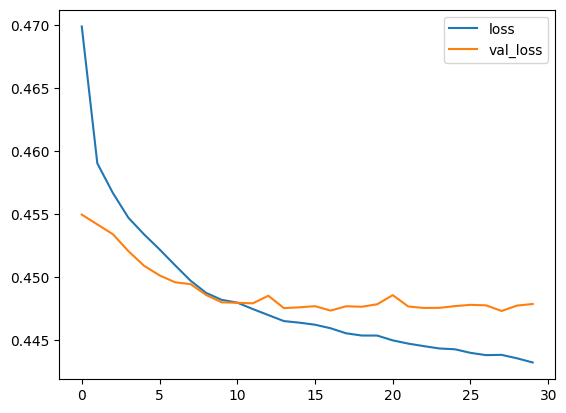

In [ ]:
error_df.plot()

In [ ]:
predictions1=lendingModel_n.predict(X_test_s)

3713/3713 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step


In [ ]:
predictions1

array([[0.80393493],
       [0.6326865 ],
       [0.92597294],
       ...,
       [0.8730795 ],
       [0.9702962 ],
       [0.87959504]], dtype=float32)

In [ ]:
pred_log = (predictions1 >= 0.5).astype(int).ravel()


In [ ]:
pred_log

array([1, 1, 1, ..., 1, 1, 1])

In [ ]:
set(pred_log)

{np.int64(0), np.int64(1)}

In [ ]:
print(confusion_matrix(pred_log,Y_test))

[[ 1797  1510]
 [21463 94039]]


In [ ]:
print(classification_report(pred_log,Y_test))

              precision    recall  f1-score   support

           0       0.08      0.54      0.14      3307
           1       0.98      0.81      0.89    115502

    accuracy                           0.81    118809
   macro avg       0.53      0.68      0.51    118809
weighted avg       0.96      0.81      0.87    118809



In [ ]:
lendingModel_n.save("/content/lend.keras")


In [ ]:
lendingModel_n.save("/content/drive/MyDrive/lend.keras")


In [ ]:
ls


drive/  lend.keras  sample_data/


In [ ]:
!ls -lh /content


total 160K
drwx------ 5 root root 4.0K Feb  7 08:54 drive
-rw-r--r-- 1 root root 151K Feb  7 11:37 lend.keras
drwxr-xr-x 1 root root 4.0K Jan 16 14:24 sample_data


In [ ]:
pwd

'/content'